# Model exploration
Looks inside one trained model: the data it learned from, how inputs are transformed, which
features were kept, what drives its scores (SHAP), how well its probabilities match reality, and
how it compared with its shadow model in production.

Run after the Airflow pipeline. It only reads `model_bank/` and `datamart/`; it changes nothing.
Use the project's `.venv` kernel: it has the same scikit-learn and XGBoost versions as the
container, so the saved models load. Figures are saved to `notebooks/figures/` for slides.

The **Takeaway** notes under each chart describe `credit_model_2024_01_01_logreg`. With another `VERSION`, the charts update but the notes do not.

In [1]:
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss, roc_auc_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "model_bank").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
from utils import model_utils as mu

FIGURES = ROOT / "notebooks" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
config = mu.load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def save(fig, name):
    fig.savefig(FIGURES / f"{VERSION}_{name}.png", dpi=200, bbox_inches="tight")


display(mu.read_registry())

C:\Users\Benedict\Documents\Coding Projects\MLE Assignment 2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,decision_date,model_version,promoted,model_type,challenger_oot_auc,challenger_oot_gini,champion_before,champion_oot_auc,reason
0,2024-01-01,credit_model_2024_01_01_logreg,True,logistic_regression,0.8307,0.6614,NaN,NaN,first_model
1,2024-07-01,credit_model_2024_07_01_xgboost,True,xgboost,0.8092,0.6185,credit_model_2024_01_01_logreg,NaN,champion_features_unavailable
2,2025-01-01,credit_model_2025_01_01_xgboost,False,xgboost,0.8231,0.6461,credit_model_2024_07_01_xgboost,0.8149,insufficient_auc_gain


## 1. Pick a model
Change `VERSION` to any folder in `model_bank/`. The train, validation and OOT rows are rebuilt with
the same code and random seed the pipeline used, so they are the exact rows the model saw.

In [2]:
# List every model in the model bank with its promotion decision.
# The project's model registry is model_bank/model_registry.csv (no MLflow server needed).
import json

rows = []
for folder in sorted((ROOT / mu.MODEL_BANK).glob("credit_model_*")):
    meta = json.load(open(folder / "metadata.json", encoding="utf-8"))
    rows.append({
        "model_version": meta["model_version"],
        "model_type": meta["model_type"],
        "runner_up (shadow)": meta["runner_up"],
        "trained_on_labels": " to ".join(meta["data"]["label_months"]),
        "gini_val": meta["metrics"]["gini_val"],
        "gini_oot": meta["metrics"]["gini_oot"],
        "calibrated": meta["calibration"]["applied"],
        "n_features": sum(len(v) for v in meta["features"].values()),
    })
models = pd.DataFrame(rows).merge(
    mu.read_registry()[["model_version", "promoted", "reason", "champion_before"]], on="model_version", how="left")
models["champion_now"] = models["model_version"] == mu.champion_as_of("9999-12-31")
display(models)

,model_version,model_type,runner_up (shadow),trained_on_labels,gini_val,gini_oot,calibrated,n_features,promoted,reason,champion_before,champion_now
0,credit_model_2024_01_01_logreg,logistic_regression,xgboost,2023-07-01 to 2024-01-01,0.5967,0.6614,False,55,True,first_model,NaN,False
1,credit_model_2024_07_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2024-07-01,0.6307,0.6185,False,38,True,champion_features_unavailable,credit_model_2024_01_01_logreg,True
2,credit_model_2025_01_01_xgboost,xgboost,logistic_regression,2023-07-01 to 2025-01-01,0.6024,0.6461,False,36,False,insufficient_auc_gain,credit_model_2024_07_01_xgboost,False


> **Takeaway:** Three models were trained. Logistic regression 2024-01 was the first champion. XGBoost 2024-07 replaced it because applicants stopped having clickstream data. XGBoost 2025-01 was not promoted: its OOT AUC gain (+0.008) was below the 0.01 rule. Calibration did not help any of them.

In [3]:
VERSION = "credit_model_2024_01_01_logreg"

artefact = mu.load_artefact(VERSION)
train_date = artefact["data"]["train_date"]
data = mu.load_training_data(train_date)
train, val, oot = mu.split_train_val_oot(data, config)
features = artefact["features"]
base = artefact["base_pipeline"]          # the model before calibration
final = artefact["pipeline"]              # what inference uses
runner_up = artefact["runner_up"]         # the shadow model

print("model type:     ", artefact["model_type"], "-", artefact["selection_reason"])
print("runner-up:      ", runner_up["model_type"])
print("calibration:    ", "applied" if artefact["calibration"]["applied"] else "not applied")
print("rows:           ", artefact["data"]["rows"])
print("bad rate:       ", artefact["data"]["bad_rate"])
print("label months:   ", artefact["data"]["label_months"], "OOT:", artefact["data"]["oot_label_months"])
print("packages:       ", artefact["lineage"]["packages"])

labelled loans known on 2024-01-01: 3556, with features: 3556
model type:      logistic_regression - highest validation Gini
runner-up:       xgboost
calibration:     not applied
rows:            {'train': 2054, 'val': 514, 'oot': 988}
bad rate:        {'train': 0.2848, 'val': 0.286, 'oot': 0.2804}
label months:    ['2023-07-01', '2024-01-01'] OOT: ['2023-12-01', '2024-01-01']
packages:        {'scikit-learn': '1.6.1', 'xgboost': '2.1.4', 'pandas': '2.1.4', 'numpy': '1.26.4'}


## 2. Default rate by label month
Each bar is the loans whose 6-month outcome was observed that month. The newest two months are
the out-of-time (OOT) test set; everything before is split 80/20 into train and validation.

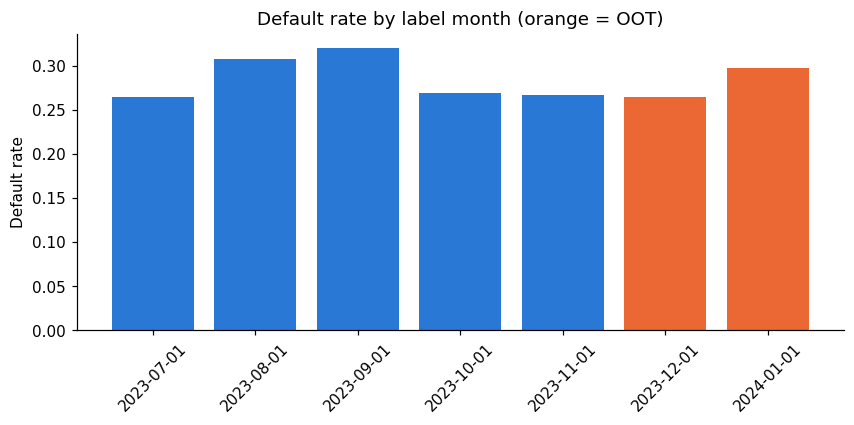

label_snapshot_date,2023-07-01,2023-08-01,2023-09-01,2023-10-01,2023-11-01,2023-12-01,2024-01-01
mean,0.264,0.307,0.32,0.269,0.267,0.265,0.297
size,530.000,501.000,506.00,510.000,521.000,517.000,471.000


In [4]:
by_month = data.groupby("label_snapshot_date")["label"].agg(["mean", "size"])
is_oot = by_month.index.isin(artefact["data"]["oot_label_months"])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(by_month.index, by_month["mean"], color=np.where(is_oot, "#eb6834", "#2a78d6"))
ax.set(title="Default rate by label month (orange = OOT)", ylabel="Default rate")
ax.tick_params(axis="x", rotation=45)
save(fig, "default_rate_by_month")
plt.show()
display(by_month.round(3).T)

> **Takeaway:** The default rate stays between 26% and 32% in every label month, with about 500 loans each, so no month is unusual. The two OOT months (26.5% and 29.7%) look like the training months.

## 3. Transformations
Money columns are heavily skewed: a few very large values. Logistic regression uses their
`log1p` version (log of 1 + value), which pulls the long tail in; XGBoost uses raw values because
trees only care about order. Inside the model pipeline, numbers are filled with the training
median and standardised (logistic regression only), flags are filled with the most common value,
and categories are one-hot encoded with "Unknown" for missing.

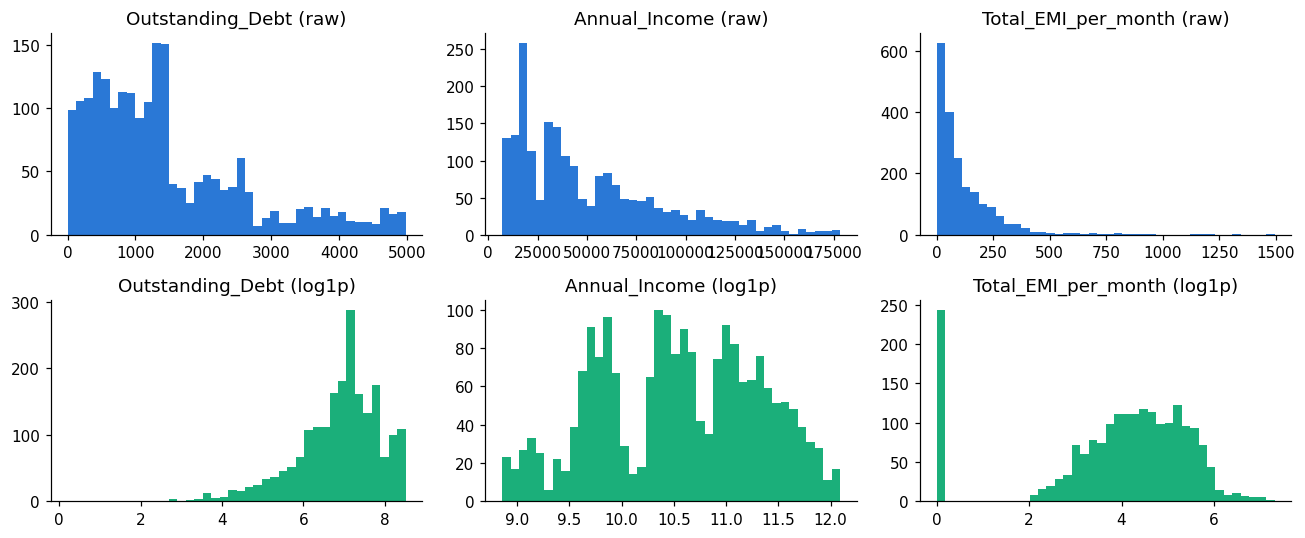

In [5]:
money = ["Outstanding_Debt", "Annual_Income", "Total_EMI_per_month"]
fig, axes = plt.subplots(2, len(money), figsize=(12, 5))
for i, column in enumerate(money):
    values = pd.to_numeric(train[column], errors="coerce").dropna()
    axes[0, i].hist(values, bins=40, color="#2a78d6")
    axes[0, i].set_title(column + " (raw)")
    axes[1, i].hist(np.log1p(values.clip(lower=0)), bins=40, color="#1baf7a")
    axes[1, i].set_title(column + " (log1p)")
fig.tight_layout()
save(fig, "log_transform")
plt.show()

> **Takeaway:** Money columns have a long right tail: monthly EMI has a median of 69 but a maximum of 1,495 (skew 3.4). After `log1p`, annual income is almost symmetric (skew -0.1) and the others tip slightly the other way (-1.1), which is still far more even. Logistic regression uses the log versions; XGBoost uses the raw values, because trees only care about order.

In [6]:
# one applicant before and after the pipeline's preprocessing step
X_train = mu.prepare_X(train, features)
preprocess = base.named_steps["preprocess"]
names = [mu._readable(n) for n in preprocess.get_feature_names_out()]
after = pd.Series(np.asarray(preprocess.transform(X_train.iloc[[0]]), dtype=float)[0], index=names)

before = X_train.iloc[0]
example = [c for c in features["numeric"][:5] + features["categorical"][:2]]
display(pd.DataFrame({"raw value": before[example]}))
display(after[[n for n in names if any(n.startswith(c) for c in example)]].round(3).to_frame("model input"))

,raw value
Age,37.0
Num_Bank_Accounts,10.0
Num_Credit_Card,7.0
Interest_Rate,25.0
Delay_from_due_date,58.0
Occupation,Engineer
Credit_Mix,Bad


,model input
Age,0.320
Num_Bank_Accounts,1.800
Num_Credit_Card,0.699
Interest_Rate,1.208
Delay_from_due_date,2.488
Occupation_Accountant,0.000
Occupation_Architect,0.000
Occupation_Developer,0.000
Occupation_Doctor,0.000
Occupation_Engineer,1.000


> **Takeaway:** Numbers become distances from the training average in standard deviations: 58 days past due is 2.5 standard deviations above a typical applicant. `Occupation` becomes 16 columns with a single 1.

In [7]:
missing = X_train.isna().mean().sort_values(ascending=False).head(10)
display(missing.round(3).to_frame("share missing in train"))

,share missing in train
fe_9_mean,0.206
fe_2_mean,0.206
fe_10_mean,0.206
fe_12_mean,0.206
fe_11_mean,0.206
fe_14_mean,0.206
fe_1_mean,0.206
fe_17_mean,0.206
fe_16_mean,0.206
fe_18_mean,0.206


> **Takeaway:** The clickstream averages are missing for 20.6% of training loans: applicants with no browsing history before they applied. Logistic regression fills these with the training median; XGBoost learns which way a missing value should push.

## 4. Feature selection
Information value (IV) measures how well one feature separates defaulters from non-defaulters on
the training split (higher is better: below 0.02 not useful, 0.1 to 0.3 medium, above 0.3 strong).
Weak features are dropped, and of two near-duplicate features (Spearman correlation above 0.9)
the one with lower IV is dropped.

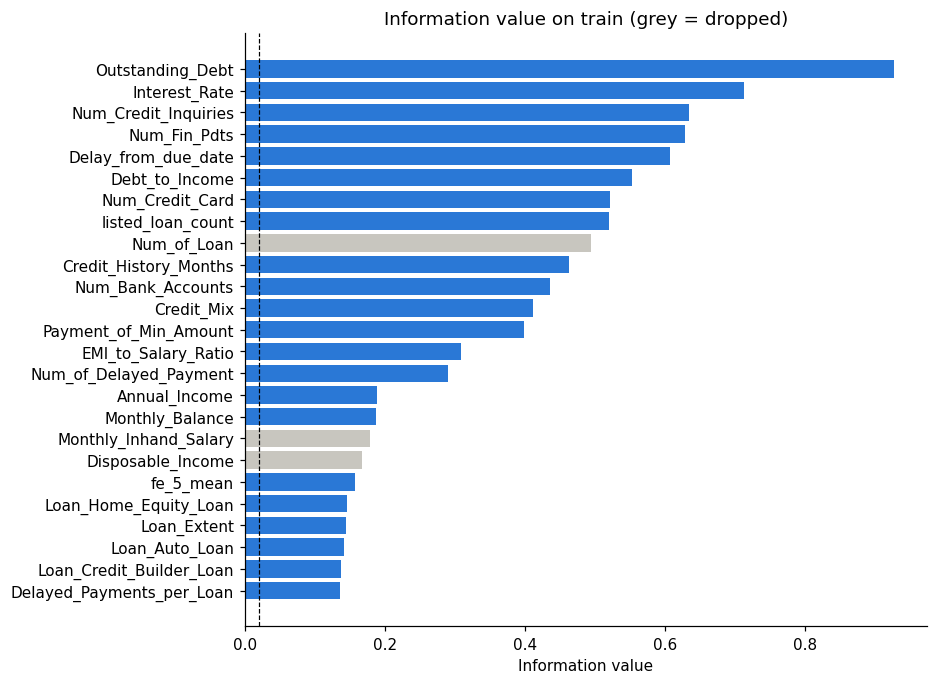

,feature,information_value,dropped
8,Num_of_Loan,0.4943,duplicate of listed_loan_count
17,Monthly_Inhand_Salary,0.1786,duplicate of Annual_Income
18,Disposable_Income,0.1680,duplicate of Annual_Income
58,fe_13_mean,0.0181,weak
59,fe_15_mean,0.0177,weak
60,fe_20_mean,0.0168,weak
61,fe_6_mean,0.0149,weak
62,interest_rate_invalid,0.0044,weak
63,num_credit_card_invalid,0.0027,weak
64,has_clickstream,0.0021,weak


In [8]:
report = pd.DataFrame(artefact["feature_report"])
top = report.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top["feature"], top["information_value"],
        color=np.where(top["dropped"] == "", "#2a78d6", "#c8c6bf"))
ax.axvline(config["training"]["min_information_value"], color="black", linestyle="--", linewidth=0.8)
ax.set(title="Information value on train (grey = dropped)", xlabel="Information value")
save(fig, "information_value")
plt.show()
display(report[report["dropped"] != ""].round(4))

> **Takeaway:** 18 of 73 candidate features were dropped: 15 as weak (mostly the `*_invalid` flags and four clickstream averages, information value below 0.02) and 3 as duplicates (`Num_of_Loan` of `listed_loan_count`; `Monthly_Inhand_Salary` and `Disposable_Income` of `Annual_Income`). The strongest single features are `Outstanding_Debt` (0.93), `Interest_Rate` (0.71) and `Num_Credit_Inquiries` (0.64).

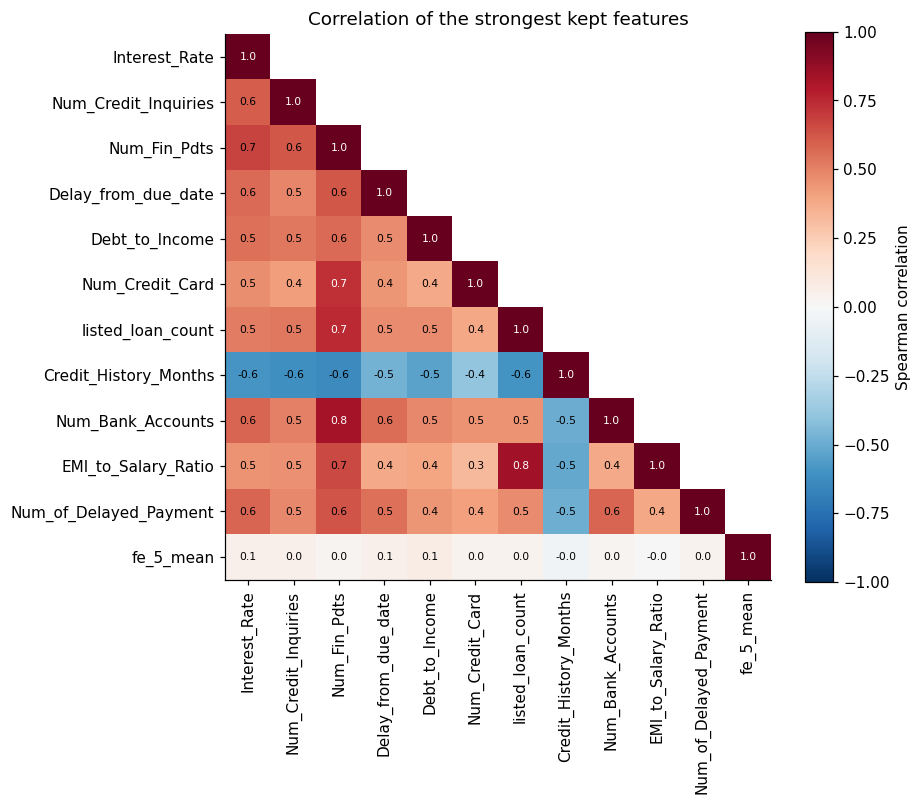

In [9]:
kept_numeric = [c for c in report.loc[report["dropped"] == "", "feature"] if c in features["numeric"]][:12]
corr = train[kept_numeric].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
# keep the lower triangle and the diagonal: each pair once, no mirror image;
# the diagonal of 1.0 is each feature against itself
corr = corr.where(np.tril(np.ones(corr.shape, dtype=bool)))
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
fig.colorbar(image, ax=ax, label="Spearman correlation")
for (i, j), value in np.ndenumerate(corr.values):
    if not np.isnan(value):
        ax.text(j, i, f"{value:.1f}", ha="center", va="center", fontsize=7,
                color="white" if abs(value) > 0.7 else "black")
ax.set_title("Correlation of the strongest kept features")
save(fig, "correlation")
plt.show()

> **Takeaway:** Most kept features are moderately related (0.4 to 0.7): customers with more financial products also have more inquiries and higher rates. The two strongest pairs, `Num_Bank_Accounts` with `Num_Fin_Pdts` (0.83) and `EMI_to_Salary_Ratio` with `listed_loan_count` (0.84), stay below the 0.9 pruning line. A longer credit history moves the other way (-0.4 to -0.6). `fe_5_mean` is unrelated to all of them, so it adds separate information.

## 5. Model comparison
Gini = 2 x AUC - 1 (higher is better). A big drop from train to validation means the model
memorised its training data (overfitting). The model type is picked on validation; OOT is only
reported.

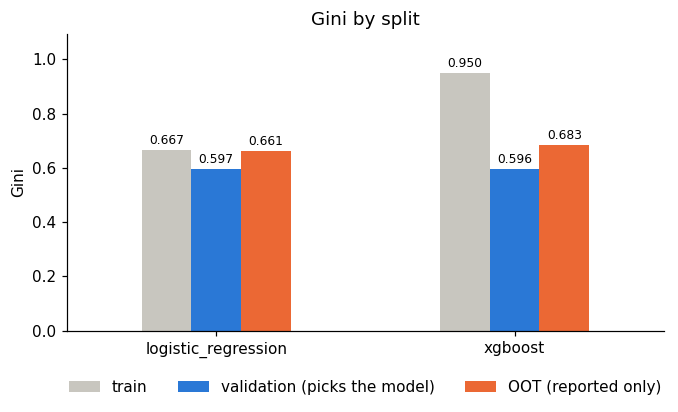

,gini_train,gini_val,gini_oot
logistic_regression,0.667,0.597,0.661
xgboost,0.950,0.596,0.683


In [10]:
scores = pd.DataFrame({t: c["scores"] for t, c in artefact["candidates"].items()}).T
gini = scores[["gini_train", "gini_val", "gini_oot"]]
ax = gini.plot.bar(figsize=(7, 3.5), rot=0, color=["#c8c6bf", "#2a78d6", "#eb6834"])
for bars in ax.containers:  # print each bar's value on top of it
    ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
ax.set(title="Gini by split", ylabel="Gini", ylim=(0, gini.values.max() * 1.15))
ax.legend(["train", "validation (picks the model)", "OOT (reported only)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False)
save(ax.figure, "model_comparison")
plt.show()
display(gini.round(3))

> **Takeaway:** The two models tie on validation (0.597 vs 0.596), so the tie-break kept the simpler logistic regression. XGBoost scores 0.950 on its own training loans but 0.596 on validation, a sign it memorised much of the training data. OOT leans towards XGBoost (0.683 vs 0.661), but OOT is only reported and never used to choose.

## 6. What drives the score: SHAP
SHAP splits each applicant's score into one push per input, measured from the average applicant
(on the log-odds scale). Positive pushes towards default. 6a gives the big picture per original
feature, 6b shows the direction of each push, 6c lists the individual model columns, and 6d checks which features the model actually needs for accuracy.

In [11]:
def explain(pipeline, background, rows):
    """SHAP values for the model inside a pipeline, with readable feature names."""
    preprocess, model = pipeline.named_steps["preprocess"], pipeline.named_steps["model"]
    names = [mu._readable(n) for n in preprocess.get_feature_names_out()]
    matrix = pd.DataFrame(np.asarray(preprocess.transform(rows), dtype=float), columns=names)
    if hasattr(model, "coef_"):
        reference = np.asarray(preprocess.transform(background), dtype=float)
        explainer = shap.LinearExplainer(model, reference)
    else:
        explainer = shap.TreeExplainer(model)
    return explainer(matrix)


X_oot = mu.prepare_X(oot, features)
shap_values = explain(base, X_train, X_oot)
print('SHAP values:', shap_values.values.shape, '(applicants x model columns)')

SHAP values: (988, 83) (applicants x model columns)


### 6a. By original feature
One-hot encoding splits a category into one column per level (`Spending_Behaviour_High`,
`Spending_Behaviour_Low`, ...), and the clickstream averages are 16 to 20 separate columns, so each
piece looks small. SHAP values add up exactly, so summing the pieces per applicant gives each
original feature's total push. Levels are always kept or dropped together; this chart only
changes how they are reported.

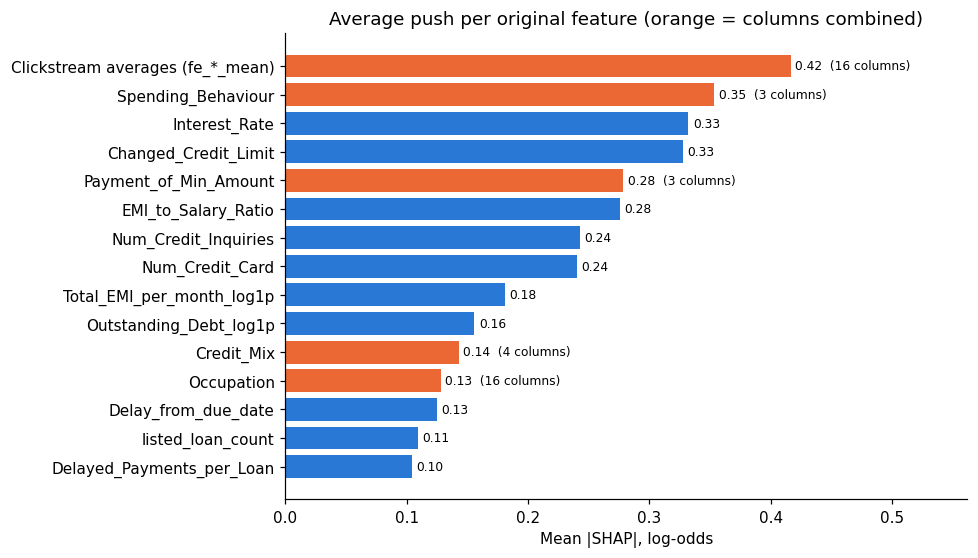

,mean |SHAP|,columns
Clickstream averages (fe_*_mean),0.417,16
Spending_Behaviour,0.353,3
Interest_Rate,0.332,1
Changed_Credit_Limit,0.328,1
Payment_of_Min_Amount,0.279,3
EMI_to_Salary_Ratio,0.275,1
Num_Credit_Inquiries,0.243,1
Num_Credit_Card,0.240,1
Total_EMI_per_month_log1p,0.181,1
Outstanding_Debt_log1p,0.156,1


In [12]:
def original_feature(column):
    """Map a model column back to the input it came from."""
    for category in features["categorical"]:
        if column.startswith(category + "_"):
            return category
    if column.startswith("fe_") and column.endswith("_mean"):
        return "Clickstream averages (fe_*_mean)"
    if column.startswith("Loan_") and column != "Loan_Extent":
        return "Loan type counts (Loan_*)"
    return column


per_applicant = pd.DataFrame(shap_values.values, columns=shap_values.feature_names)
grouped = per_applicant.T.groupby(original_feature).sum().T     # one total push per original feature
importance = grouped.abs().mean().sort_values(ascending=False)
pieces = pd.Series(shap_values.feature_names).map(original_feature).value_counts()

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.barh(top.index, top.values,
               color=["#eb6834" if pieces[name] > 1 else "#2a78d6" for name in top.index])
ax.bar_label(bars, labels=[f"{v:.2f}" + (f"  ({pieces[n]} columns)" if pieces[n] > 1 else "")
                           for n, v in zip(top.index, top.values)], fontsize=8, padding=3)
ax.set(title="Average push per original feature (orange = columns combined)",
       xlabel="Mean |SHAP|, log-odds", xlim=(0, top.max() * 1.35))
save(fig, "shap_importance_grouped")
plt.show()
display(importance.round(3).to_frame("mean |SHAP|").join(pieces.rename("columns")).head(20))

> **Takeaway:** Taken together, the clickstream averages are the biggest driver of the 2024-01 model (0.42), ahead of `Spending_Behaviour` (0.35) and `Interest_Rate` (0.33). Applicants have no clickstream from July 2024, so this model could not stay in production past June 2024.

### 6b. Direction of each push
Every OOT applicant is a dot. Colour is the feature's value (red high, blue low); position is its
push (right = towards default).

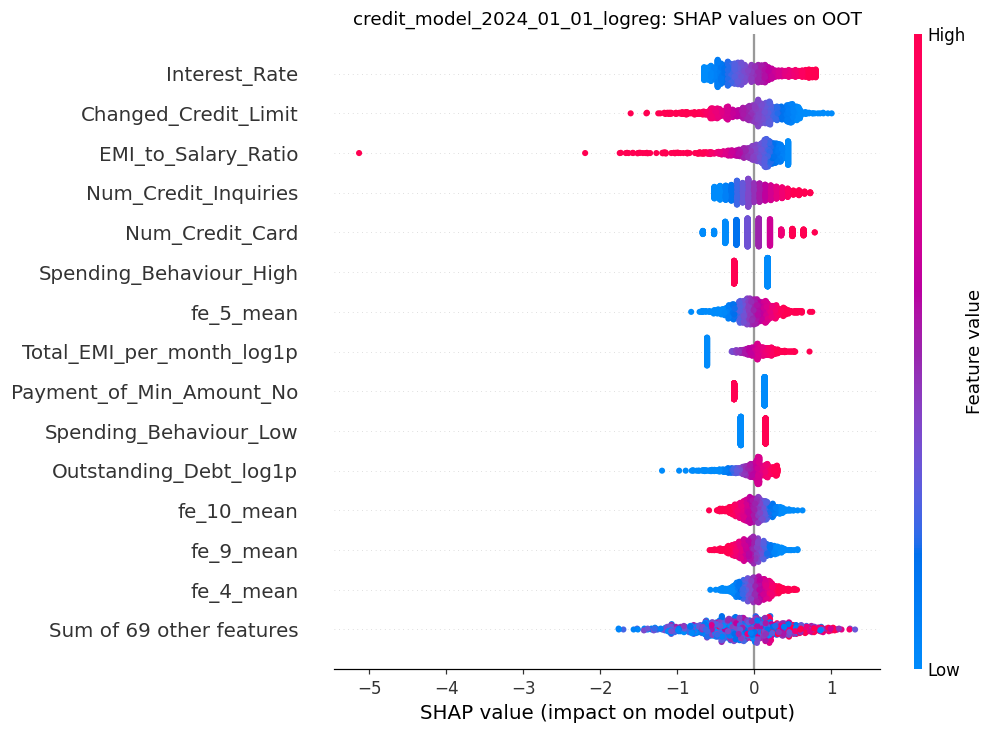

In [13]:
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.title(f"{VERSION}: SHAP values on OOT")
save(plt.gcf(), "shap_beeswarm")
plt.show()

> **Takeaway:** High interest rates, many credit inquiries and many credit cards push towards default, as expected. A high `Changed_Credit_Limit` and a high `EMI_to_Salary_Ratio` push away from default. The second runs against intuition: it overlaps strongly with `listed_loan_count` (correlation 0.84) and `Total_EMI_per_month_log1p`, so the model splits one effect across them. Read related features together, not one by one.

### 6c. Per model column
The same pushes per individual model column, before grouping.

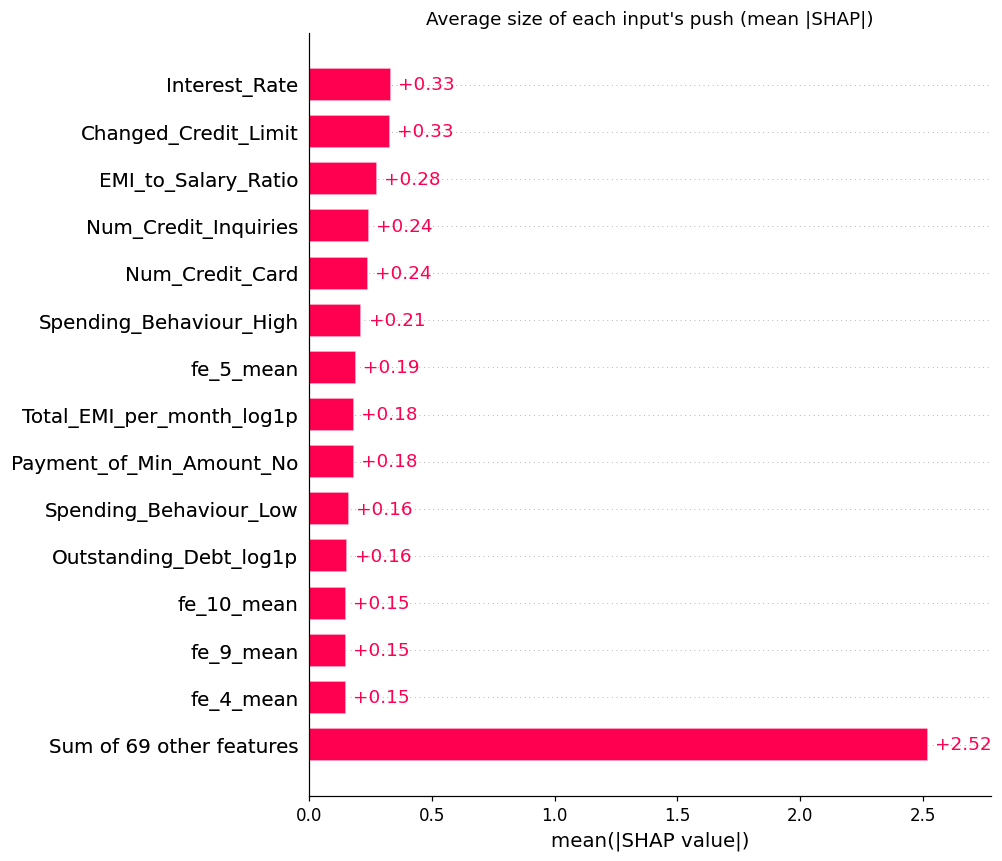

In [14]:
shap.plots.bar(shap_values, max_display=15, show=False)
plt.title("Average size of each input's push (mean |SHAP|)")
save(plt.gcf(), "shap_importance")
plt.show()

> **Takeaway:** Per column, `Interest_Rate` leads (0.33). Category levels such as `Spending_Behaviour_High` and `_Low` appear as separate, smaller bars, and the 69 smallest columns are summed into one row, which is why 6a groups them.

### 6d. What the model needs: permutation importance
SHAP shows how much a feature moves the score. Permutation importance asks a different question:
how much accuracy is lost when a feature's values are shuffled between OOT applicants, which breaks
its link to the outcome. Each feature (with all its one-hot columns, and the clickstream averages as
one group) is shuffled 20 times. A bigger drop means the model needs it more; a drop near zero
means other features already carry the same information.

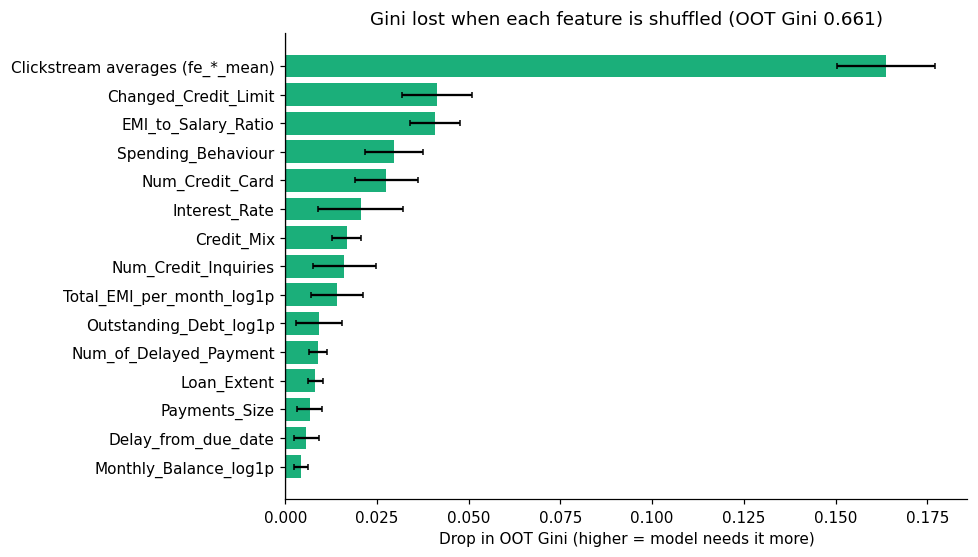

most needed:


,feature,gini_lost,spread,shap_rank
0,Clickstream averages (fe_*_mean),0.164,0.013,1
1,Changed_Credit_Limit,0.041,0.010,4
2,EMI_to_Salary_Ratio,0.041,0.007,6
3,Spending_Behaviour,0.029,0.008,2
4,Num_Credit_Card,0.028,0.009,8
5,Interest_Rate,0.020,0.012,3
6,Credit_Mix,0.017,0.004,11
7,Num_Credit_Inquiries,0.016,0.009,7
8,Total_EMI_per_month_log1p,0.014,0.007,9
9,Outstanding_Debt_log1p,0.009,0.006,10


least needed (shuffling barely hurts, or even helps):


,feature,gini_lost,spread,shap_rank
27,Age,-0.002,0.001,25
28,Loan type counts (Loan_*),-0.002,0.003,16
29,Num_Bank_Accounts,-0.003,0.002,22
30,listed_loan_count,-0.006,0.003,14
31,Payment_of_Min_Amount,-0.007,0.007,5


In [15]:
def gini_on(X):
    return 2 * roc_auc_score(oot["label"], base.predict_proba(X)[:, 1]) - 1


X_shuffle = X_oot.reset_index(drop=True)
inputs = pd.Series(X_shuffle.columns, index=X_shuffle.columns).map(original_feature)
baseline_gini = gini_on(X_shuffle)
rng = np.random.default_rng(0)

rows = []
for name, columns in inputs.groupby(inputs).groups.items():
    drops = []
    for _ in range(20):
        shuffled = X_shuffle.copy()
        shuffled[list(columns)] = X_shuffle[list(columns)].values[rng.permutation(len(X_shuffle))]
        drops.append(baseline_gini - gini_on(shuffled))
    rows.append({"feature": name, "gini_lost": np.mean(drops), "spread": np.std(drops)})
permutation = pd.DataFrame(rows).sort_values("gini_lost", ascending=False, ignore_index=True)
permutation["shap_rank"] = permutation["feature"].map({f: r + 1 for r, f in enumerate(importance.index)})

top = permutation.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["feature"], top["gini_lost"], xerr=top["spread"], color="#1baf7a", capsize=2)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title=f"Gini lost when each feature is shuffled (OOT Gini {baseline_gini:.3f})",
       xlabel="Drop in OOT Gini (higher = model needs it more)")
save(fig, "permutation_importance")
plt.show()
print("most needed:")
display(permutation.head(15).round(3))
print("least needed (shuffling barely hurts, or even helps):")
display(permutation.tail(5).round(3))

> **Takeaway:** The model depends heavily on the clickstream averages: shuffling them costs 0.164 of
its 0.661 OOT Gini, four times more than any other feature, because nothing else carries the same
information. That is a risk, since these averages partly measure how long a customer has been
around (the calendar effect). The rankings disagree where features overlap: `Interest_Rate` has the
third-largest SHAP push but costs only 0.020 when shuffled, because inquiries, cards and products
tell a similar story. `Payment_of_Min_Amount` (SHAP rank 5, information value 0.40 on its own) and
`listed_loan_count` do not hurt at all when shuffled (-0.007 and -0.006, within noise): other
features already carry their information. The new `Delayed_Payments_per_Loan` adds almost nothing
to this model (0.001).

## 7. One applicant
The riskiest OOT applicant: the waterfall starts at the average score and adds each input's push.
The `reason_1` to `reason_3` columns in the predictions table are the biggest upward pushes.

predicted default probability 0.98; actually defaulted: 1


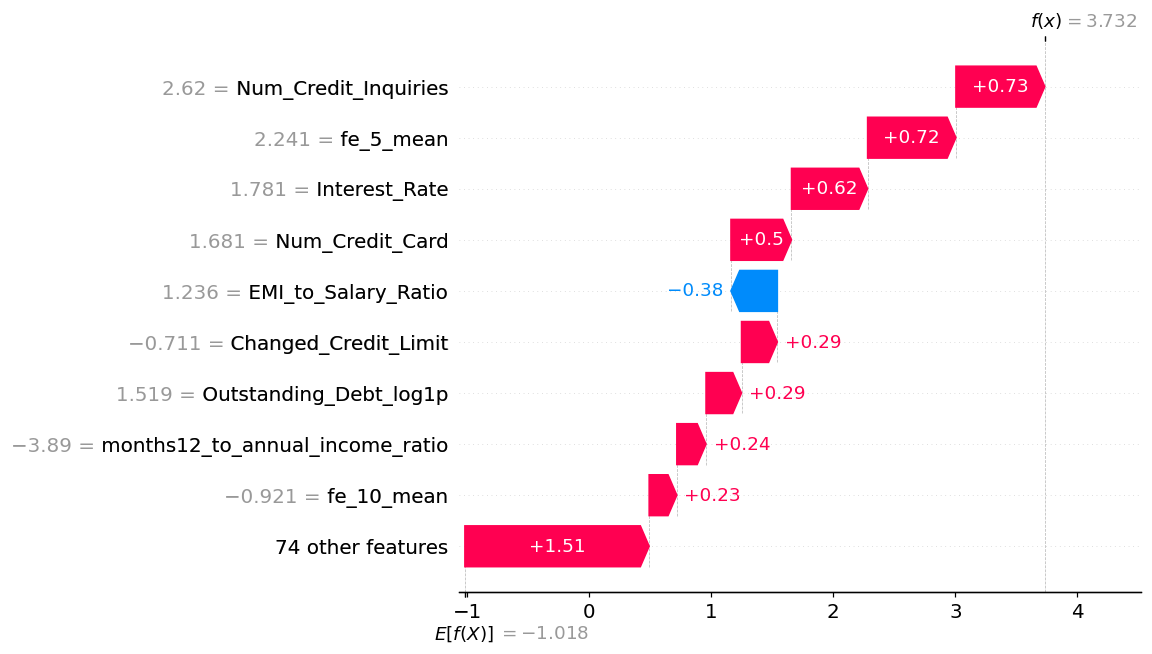

,reason_1,reason_2,reason_3
3491,Num_Credit_Inquiries,fe_5_mean,Interest_Rate


In [16]:
risk = final.predict_proba(X_oot)[:, 1]
riskiest = int(np.argmax(risk))
print(f"predicted default probability {risk[riskiest]:.2f}; actually defaulted: {oot['label'].iloc[riskiest]}")
shap.plots.waterfall(shap_values[riskiest], max_display=10, show=False)
save(plt.gcf(), "shap_waterfall")
plt.show()
display(mu.reason_codes(base, X_oot.iloc[[riskiest]]))

> **Takeaway:** The riskiest OOT applicant was predicted 0.98 and did default. The biggest pushes were 17 credit inquiries (+0.76), a high `fe_5_mean` (+0.75), a 30% interest rate (+0.68) and 9 credit cards (+0.50). The first three are the reason codes stored with that prediction.

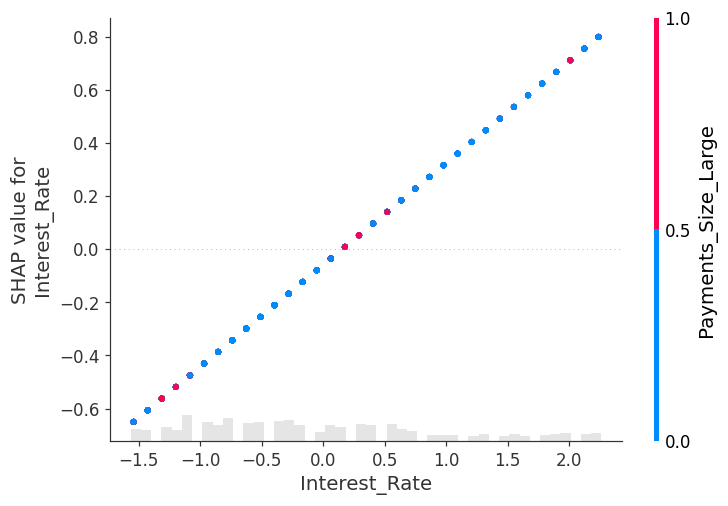

In [17]:
top_feature = shap_values.abs.mean(0).values.argmax()
shap.plots.scatter(shap_values[:, top_feature], color=shap_values, show=False)
save(plt.gcf(), "shap_dependence")
plt.show()

> **Takeaway:** `Interest_Rate` is the column with the largest average push. For logistic regression the line is always straight: each step up in interest rate adds the same push. The x-axis is in standard deviations from the average rate (the scaled model input), and the colour adds nothing here because a straight-line model has no interactions. An XGBoost model would show steps and curves.

## 8. The shadow model
The runner-up scored the same applicants in production without affecting decisions. Comparing
what each model relies on shows whether they learned the same story.

In [18]:
X_oot_shadow = mu.prepare_X(oot, runner_up["features"])
X_train_shadow = mu.prepare_X(train, runner_up["features"])
shadow_values = explain(runner_up["pipeline"], X_train_shadow, X_oot_shadow)

top_champion = pd.Series(np.abs(shap_values.values).mean(0), index=shap_values.feature_names).nlargest(10)
top_shadow = pd.Series(np.abs(shadow_values.values).mean(0), index=shadow_values.feature_names).nlargest(10)
display(pd.DataFrame({f"champion ({artefact['model_type']})": top_champion.index,
                      f"shadow ({runner_up['model_type']})": top_shadow.index}))

,champion (logistic_regression),shadow (xgboost)
0,Interest_Rate,Outstanding_Debt
1,Changed_Credit_Limit,fe_5_mean
2,EMI_to_Salary_Ratio,Delay_from_due_date
3,Num_Credit_Inquiries,fe_9_mean
4,Num_Credit_Card,Changed_Credit_Limit
5,Spending_Behaviour_High,Spending_Behaviour_High
6,fe_5_mean,Interest_Rate
7,Total_EMI_per_month_log1p,fe_10_mean
8,Payment_of_Min_Amount_No,fe_4_mean
9,Spending_Behaviour_Low,fe_7_mean


> **Takeaway:** Both models use `Changed_Credit_Limit`, `Spending_Behaviour` and `Interest_Rate`. XGBoost leans much more on `Outstanding_Debt`, `Delay_from_due_date` and the clickstream averages (5 of its top 10).

,gini,gini_pooled,credit_model_2024_01_01_xgboost_runner_up
cohort_date,,,
2024-01-01,0.673,0.673,0.750
2024-02-01,0.679,0.675,0.734
2024-03-01,0.661,0.670,0.736
2024-04-01,0.644,0.661,0.724
2024-05-01,0.732,0.679,0.746
2024-06-01,0.743,0.706,0.764


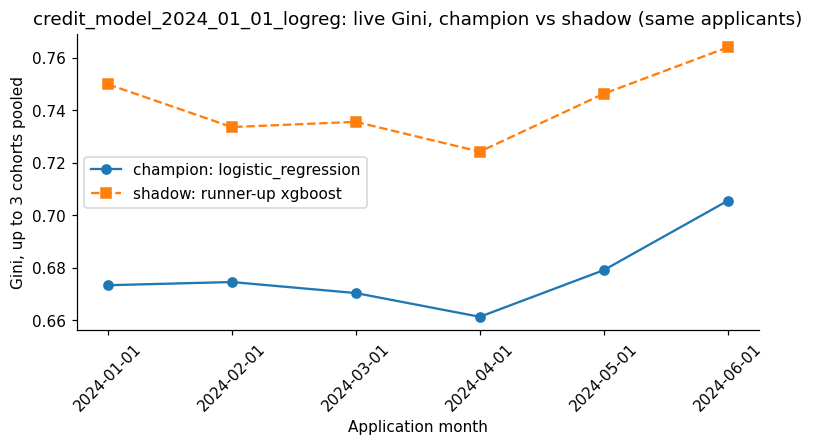

In [19]:
monitoring = pd.concat([pd.read_parquet(p) for p in sorted((ROOT / mu.MONITORING).glob("monitoring_*.parquet"))])
live = monitoring[monitoring["model_version"] == VERSION]
champion_live = live[live["metric_type"] == "performance"].set_index("cohort_date")[["gini", "gini_pooled"]]
shadow_live = live[live["metric_type"] == "shadow"].pivot_table(index="cohort_date", columns="shadow_model",
                                                               values="gini_pooled")
table = champion_live.join(shadow_live)
display(table.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(table.index, table["gini_pooled"], marker="o", label=f"champion: {artefact['model_type']}")
for column in shadow_live.columns:
    kind = f"runner-up {runner_up['model_type']}" if column.endswith("_runner_up") else "rejected challenger " + column
    ax.plot(table.index, table[column], marker="s", linestyle="--", label=f"shadow: {kind}")
ax.set(title=f"{VERSION}: live Gini, champion vs shadow (same applicants)", ylabel="Gini, up to 3 cohorts pooled",
       xlabel="Application month")
ax.legend()
ax.tick_params(axis="x", rotation=45)
save(fig, "shadow_live_gini")
plt.show()

> **Takeaway:** On the same applicants, the XGBoost shadow ranked defaulters better in every month from January to June 2024: pooled Gini 0.72 to 0.76 against 0.66 to 0.71. No shadow flag fired because three months of labels only existed from September 2024, when XGBoost 2024-07 was already champion.

## 9. Calibration
Do the probabilities match reality? Group OOT applicants into 10 bins by score and compare each
bin's average score with its actual default rate. Perfect calibration lies on the diagonal.
Platt scaling is fitted on validation and kept only if it lowers the Brier score on OOT
(lower is better).

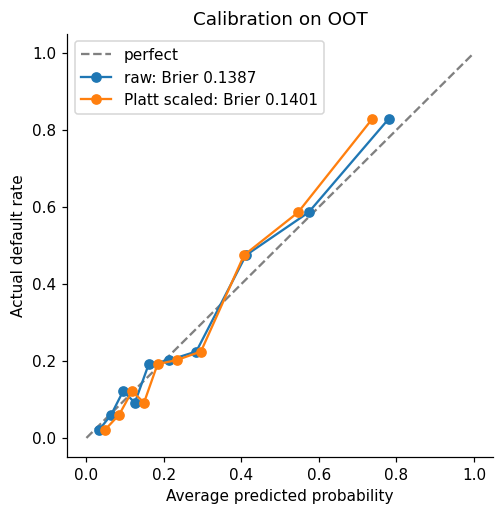

,saved in artefact
method,platt (sigmoid) on validation
brier_oot_raw,0.1387
brier_oot_calibrated,0.1401
mean_prediction_oot_raw,0.2739
mean_prediction_oot_calibrated,0.2801
bad_rate_oot,0.2804
applied,False


In [20]:
platt = CalibratedClassifierCV(FrozenEstimator(base), method="sigmoid").fit(mu.prepare_X(val, features), val["label"])
raw = base.predict_proba(X_oot)[:, 1]
adjusted = platt.predict_proba(X_oot)[:, 1]

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
for name, probs in [("raw", raw), ("Platt scaled", adjusted)]:
    actual, predicted = calibration_curve(oot["label"], probs, n_bins=10, strategy="quantile")
    ax.plot(predicted, actual, marker="o",
            label=f"{name}: Brier {brier_score_loss(oot['label'], probs):.4f}")
ax.set(title="Calibration on OOT", xlabel="Average predicted probability", ylabel="Actual default rate")
ax.legend()
save(fig, "calibration_curve")
plt.show()
display(pd.Series(artefact["calibration"]).to_frame("saved in artefact"))

> **Takeaway:** The raw probabilities already sit close to the diagonal: 27.4% predicted against 28.0% actual on OOT. Platt scaling made the Brier score slightly worse (0.1387 to 0.1401, lower is better), so the pipeline kept the raw model.

## 10. Reason codes in production
How often each input was the top reason behind a score, across every month this model scored.

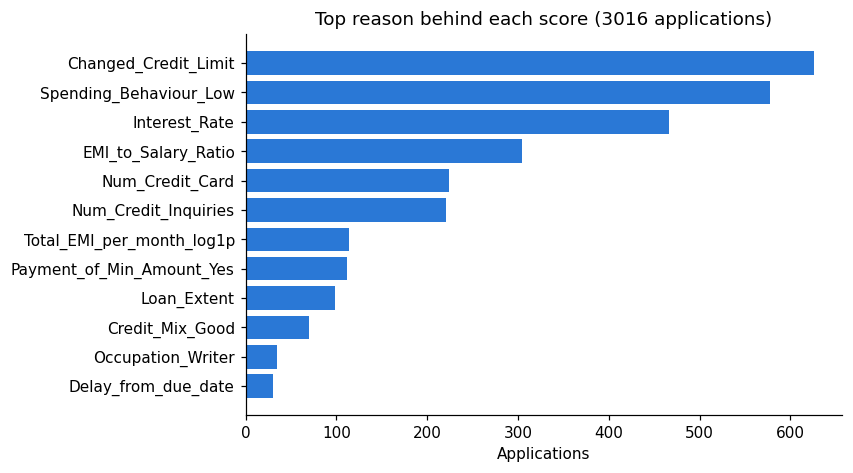

In [21]:
predictions = pd.concat([pd.read_parquet(p) for p in sorted((ROOT / mu.PREDICTIONS).glob("predictions_*.parquet"))])
mine = predictions[predictions["model_version"] == VERSION]
counts = mine["reason_1"].value_counts().head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(counts.index, counts.values, color="#2a78d6")
ax.set(title=f"Top reason behind each score ({len(mine)} applications)", xlabel="Applications")
save(fig, "reason_codes")
plt.show()

> **Takeaway:** Across 3,016 applications scored by this model, the most common top reason is `Changed_Credit_Limit` (21%), then `Spending_Behaviour_Low` (19%) and `Interest_Rate` (16%). A small credit-limit change counts as a reason because larger changes lower risk in this model.